# Brain Tumor MRI Classification using PyTorch

---
#### DISCLAIMER: THIS IS NOT MEDICAL ADVICE, DO NOT SELF DIAGNOSE

## Imports and loading data

In [1]:
import torch
from torch import nn, optim
from torch.nn import Flatten
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")

# use gpu if it's available if not cpu which is much slower
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Image transformations
Certain transformations are needed before using an image, e.g resize, changing to tensor and normalizing

In [2]:
# Every image will go through this transformation pipeline
pic_trans = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [3]:
train_dl = DataLoader(
    datasets.ImageFolder('data/Training', pic_trans),
    batch_size=32,
    shuffle=True,
    num_workers=4, # speeds up loading data
    pin_memory=True
)

test_dl = DataLoader(
    datasets.ImageFolder('data/Testing', pic_trans),
    batch_size=32,
    shuffle=False, # there is no need to shuffle, as this is just for evaluation
    num_workers=4, # speeds up loading data
    pin_memory=True
)

## Define model

In [4]:
model = nn.Sequential(
    nn.Conv2d(3, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(128 * 16 * 16, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 4) # final layer, which takes 256 as input and 4 as output (4 classes
).to(device)

In [7]:
opt = optim.Adam(model.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()

## Training loop

In [8]:
for epoch in range(25):
    running_loss = 0

    for x, y in train_dl:
        opt.zero_grad()

        loss = loss_fn(model(x.to(device)), y.to(device))
        loss.backward()

        running_loss += loss.item()
        opt.step()

    print(f'Epoch {epoch+1}: Loss was {running_loss}')

Epoch 1: Loss was 100.37581539154053
Epoch 2: Loss was 85.71591107547283
Epoch 3: Loss was 78.64105226099491
Epoch 4: Loss was 70.83966931700706
Epoch 5: Loss was 64.23535625636578
Epoch 6: Loss was 58.76537059992552
Epoch 7: Loss was 52.8124413266778
Epoch 8: Loss was 48.32662855833769
Epoch 9: Loss was 42.55523278564215
Epoch 10: Loss was 38.83605322986841
Epoch 11: Loss was 34.47004509717226
Epoch 12: Loss was 31.977435793727636
Epoch 13: Loss was 29.43682185560465
Epoch 14: Loss was 23.95413493551314
Epoch 15: Loss was 22.429060803726315
Epoch 16: Loss was 20.436388336122036
Epoch 17: Loss was 19.246046109125018
Epoch 18: Loss was 15.88414010591805
Epoch 19: Loss was 14.649436466395855
Epoch 20: Loss was 12.423489269800484
Epoch 21: Loss was 12.090080634690821
Epoch 22: Loss was 11.370644330047071
Epoch 23: Loss was 10.21155065530911
Epoch 24: Loss was 9.476011938415468
Epoch 25: Loss was 7.71386677864939


In [9]:
model.eval()
test_loss, correct = 0.0, 0
with torch.no_grad():
    for x, y in test_dl:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        test_loss = loss_fn(logits, y).item() * y.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == y).float().sum().item()

test_loss /= len(test_dl.dataset)
accuracy = 100.0 * correct / len(test_dl.dataset)

print(f'Test set: Average loss: {test_loss}, Accuracy: {accuracy}')

Test set: Average loss: 0.006108112931251526, Accuracy: 89.375


Decent with room for improvement ;))

## Visualising image

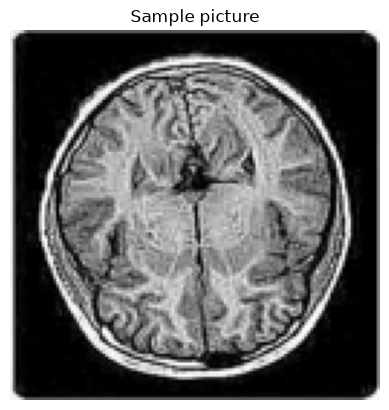

Predicted: notumor
Actual: notumor


In [11]:
import random
from torchvision.transforms.functional import to_pil_image

model.eval()

idx = random.randrange(len(test_dl.dataset))
img, label = test_dl.dataset[idx]

unnorm = img * 0.5 + 0.5
plt.imshow(to_pil_image(unnorm))
plt.axis('off')
plt.title('Sample picture')
plt.show()

with torch.no_grad():
    logits = model(img.unsqueeze(0).to(device))
    pred = logits.argmax(dim=1).item()

class_names = test_dl.dataset.classes
print(f'Predicted: {class_names[pred]}')
print(f'Actual: {class_names[label]}')

## Conclusion
Model is decent but there is room for improvement. Hyperparameter tuning, trying different architectures and optimisers, learning rates, model checkpointing.

In [12]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for x, y in test_dl:
        logits = model(x.to(device))
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(y.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
class_names = test_dl.dataset.classes

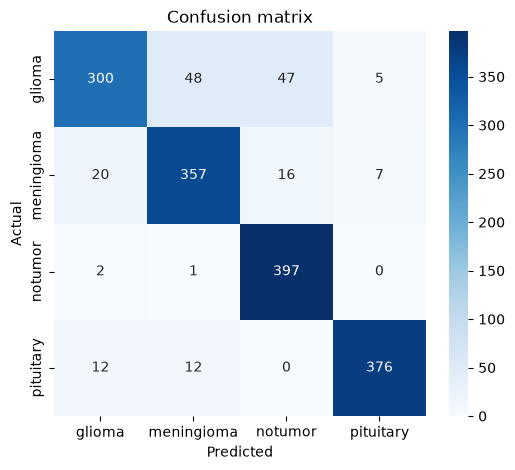

In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

In [14]:
from sklearn.metrics import classification_report

print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

              precision    recall  f1-score   support

      glioma      0.898     0.750     0.817       400
  meningioma      0.854     0.892     0.873       400
     notumor      0.863     0.993     0.923       400
   pituitary      0.969     0.940     0.954       400

    accuracy                          0.894      1600
   macro avg      0.896     0.894     0.892      1600
weighted avg      0.896     0.894     0.892      1600



In [15]:
# find the healthy class by name (e.g. 'notumor' or 'no_tumor')
healthy_idx = next(i for i, c in enumerate(class_names) if c.lower().startswith('no'))

actual_tumour = all_labels != healthy_idx
pred_tumour = all_preds != healthy_idx

false_negatives = np.sum(actual_tumour & ~pred_tumour)   # tumour missed
false_positives = np.sum(~actual_tumour & pred_tumour)   # healthy flagged as tumour
tumour_recall = np.sum(actual_tumour & pred_tumour) / np.sum(actual_tumour)

print(f'Tumour detection recall: {tumour_recall:.3f}')
print(f'Missed tumours (false negatives): {false_negatives}')
print(f'False alarms (false positives): {false_positives}')

Tumour detection recall: 0.948
Missed tumours (false negatives): 63
False alarms (false positives): 3
